# Allocating risk by recursive bisection

The variance assigned to a cluster is computed from an inverse-variance portfolio inside that cluster:

$$
\widetilde w_i^{(C)}=\frac{\sigma_i^{-2}}{\sum_{j\in C}\sigma_j^{-2}},
\qquad
V_C=(\widetilde w^{(C)})^{\mathsf T}\Sigma_C\widetilde w^{(C)}.
$$

Here, $C$ is a cluster, $i$ and $j$ label assets in that cluster, $\sigma_i^2$ is asset $i$'s variance, $\widetilde w_i^{(C)}$ is its internal inverse-variance weight, $\Sigma_C$ is the cluster covariance matrix, $V_C$ is cluster variance, and $\mathsf T$ denotes transpose.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.optimization.hrp import cluster_variance, distance_corr, hrp, inverse_variance_weights, quasi_diagonal, recursive_bisection
FIGURES = ROOT / 'outputs' / 'figures' / '25_hierarchical_risk_parity'
TABLES = ROOT / 'outputs' / 'tables' / '25_hierarchical_risk_parity'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def correlation_from_covariance(covariance):
    values = covariance.to_numpy(dtype=float)
    scales = np.sqrt(np.diag(values))
    correlation = values / np.outer(scales, scales)
    correlation = np.clip((correlation + correlation.T) / 2.0, -1.0, 1.0)
    np.fill_diagonal(correlation, 1.0)
    return pd.DataFrame(correlation, index=covariance.index, columns=covariance.columns)

def hierarchy(correlation, method='single'):
    distance = distance_corr(correlation.to_numpy(dtype=float))
    distance = (distance + distance.T) / 2.0
    np.fill_diagonal(distance, 0.0)
    condensed = squareform(distance, checks=True)
    tree = linkage(condensed, method=method)
    order = correlation.index[quasi_diagonal(tree)].tolist()
    return (distance, condensed, tree, order)

def weights_for_method(covariance, correlation, method='single'):
    _, _, tree, order = hierarchy(correlation, method)
    return (recursive_bisection(covariance, order).sort_index(), order, tree)

def global_minimum_variance(covariance):
    values = covariance.to_numpy(dtype=float)
    direction = np.linalg.solve(values, np.ones(values.shape[0]))
    weights = direction / direction.sum()
    return pd.Series(weights, index=covariance.index)

def inverse_variance_series(covariance):
    return pd.Series(inverse_variance_weights(covariance), index=covariance.index)

def portfolio_metrics(name, weights, covariance):
    aligned = weights.reindex(covariance.index).to_numpy(dtype=float)
    variance = float(aligned @ covariance.to_numpy(dtype=float) @ aligned)
    concentration = float(aligned @ aligned)
    return {'Portfolio': name, 'Annual volatility': float(np.sqrt(variance)), 'Largest weight': float(aligned.max()), 'Smallest weight': float(aligned.min()), 'Gross exposure': float(np.abs(aligned).sum()), 'Weight concentration': concentration, 'Effective holdings': float(1.0 / concentration)}

def one_way_turnover(current, previous):
    return float(0.5 * np.abs(current.sort_index().to_numpy() - previous.sort_index().to_numpy()).sum())
selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].copy()
annual_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Selected industries'], 'Value': ['49_Industry_Portfolios_daily_CSV.zip', 'Kenneth R. French Data Library', 'Daily value-weighted return', str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets)]})
save_table(data_provenance, 'allocation_data_provenance', 'Public data used for the Chapter 21 allocation study.', 'tab:chapter21-allocation-data')
display(data_provenance)
distance_values, condensed_distance, single_tree, single_order = hierarchy(public_correlation, 'single')

def traced_bisection(covariance, sorted_items):
    weights = pd.Series(1.0, index=sorted_items)
    active = [sorted_items]
    records = []
    depth = 0
    while active:
        active = [cluster[start:end] for cluster in active for start, end in ((0, len(cluster) // 2), (len(cluster) // 2, len(cluster))) if len(cluster) > 1]
        if not active:
            break
        depth += 1
        for position in range(0, len(active), 2):
            left = active[position]
            right = active[position + 1]
            left_variance = cluster_variance(covariance, left)
            right_variance = cluster_variance(covariance, right)
            left_fraction = 0.5 if left_variance + right_variance == 0 else right_variance / (left_variance + right_variance)
            incoming = float(weights.loc[left[0]])
            records.append({'Depth': depth, 'Pair': position // 2 + 1, 'Left cluster': ', '.join(left), 'Right cluster': ', '.join(right), 'Left assets': len(left), 'Right assets': len(right), 'Left variance': left_variance, 'Right variance': right_variance, 'Left fraction': left_fraction, 'Right fraction': 1.0 - left_fraction, 'Incoming multiplier': incoming})
            weights.loc[left] *= left_fraction
            weights.loc[right] *= 1.0 - left_fraction
    return (weights, pd.DataFrame(records))
traced_weights, branch_allocations = traced_bisection(annual_covariance, single_order)
released_weights = hrp(annual_covariance, public_correlation)
direct_weights = recursive_bisection(annual_covariance, single_order).sort_index()
save_table(branch_allocations, 'branch_allocations', 'Every recursive split in the public HRP allocation.', 'tab:chapter21-branch-allocations')
display(branch_allocations)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Selected industries,16


,Depth,Pair,Left cluster,Right cluster,Left assets,Right assets,Left variance,Right variance,Left fraction,Right fraction,Incoming multiplier
0,1,1,"Smoke, Fun, Hshld, Soda, Food, Beer, Toys, Agric","Clths, Txtls, Rubbr, Books, Chems, Drugs, Hlth...",8,8,0.026644,0.038853,0.593201,0.406799,1
1,2,1,"Smoke, Fun, Hshld, Soda","Food, Beer, Toys, Agric",4,4,0.028107,0.029378,0.511056,0.488944,0.593201
2,2,2,"Clths, Txtls, Rubbr, Books","Chems, Drugs, Hlth, MedEq",4,4,0.054155,0.036081,0.399850,0.600150,0.406799
3,3,1,"Smoke, Fun","Hshld, Soda",2,2,0.041167,0.030111,0.422445,0.577555,0.303159
4,3,2,"Food, Beer","Toys, Agric",2,2,0.029236,0.068783,0.701728,0.298272,0.290042
5,3,3,"Clths, Txtls","Rubbr, Books",2,2,0.090474,0.047817,0.345771,0.654229,0.162659
6,3,4,"Chems, Drugs","Hlth, MedEq",2,2,0.034371,0.047275,0.579026,0.420974,0.244140
7,4,1,Smoke,Fun,1,1,0.049930,0.094118,0.653380,0.346620,0.128068
8,4,2,Hshld,Soda,1,1,0.033222,0.036658,0.524588,0.475412,0.175091
9,4,3,Food,Beer,1,1,0.027955,0.039006,0.582519,0.417481,0.203530


## Split Fractions

A parent cluster is split so that the lower-variance child receives the larger fraction:

$$
\alpha_A=1-\frac{V_A}{V_A+V_B}=\frac{V_B}{V_A+V_B},
\qquad
w_i\leftarrow\alpha_Aw_i\ (i\in A),
\qquad
w_j\leftarrow(1-\alpha_A)w_j\ (j\in B).
$$

Here, $A$ and $B$ are sibling clusters, $V_A$ and $V_B$ are their cluster variances, $\alpha_A$ is the fraction assigned to cluster $A$, and $w_i$ and $w_j$ are the running asset weights multiplied at that split.

,Industry,HRP,Inverse variance,Equal weight,Minimum variance
0,Agric,0.051311,0.039388,0.0625,0.042351
1,Beer,0.084970,0.084592,0.0625,-0.158299
2,Books,0.052472,0.054310,0.0625,0.127191
3,Chems,0.051251,0.054517,0.0625,-0.167604
4,Clths,0.034738,0.035798,0.0625,-0.031791
5,Drugs,0.090113,0.095855,0.0625,0.310104
6,Food,0.118560,0.118033,0.0625,0.489942
7,Fun,0.044391,0.035058,0.0625,0.074315
8,Hlth,0.046918,0.055703,0.0625,-0.014714
9,Hshld,0.091851,0.099320,0.0625,0.118697


,Portfolio,Annual volatility,Largest weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
0,HRP,0.169890,0.118560,0.021505,1,0.072887,13.719837
1,Inverse variance,0.169625,0.118033,0.022161,1,0.074432,13.435053
2,Equal weight,0.185824,0.062500,0.062500,1,0.062500,16
3,Minimum variance,0.147925,0.489942,-0.167604,1.958914,0.472836,2.114899


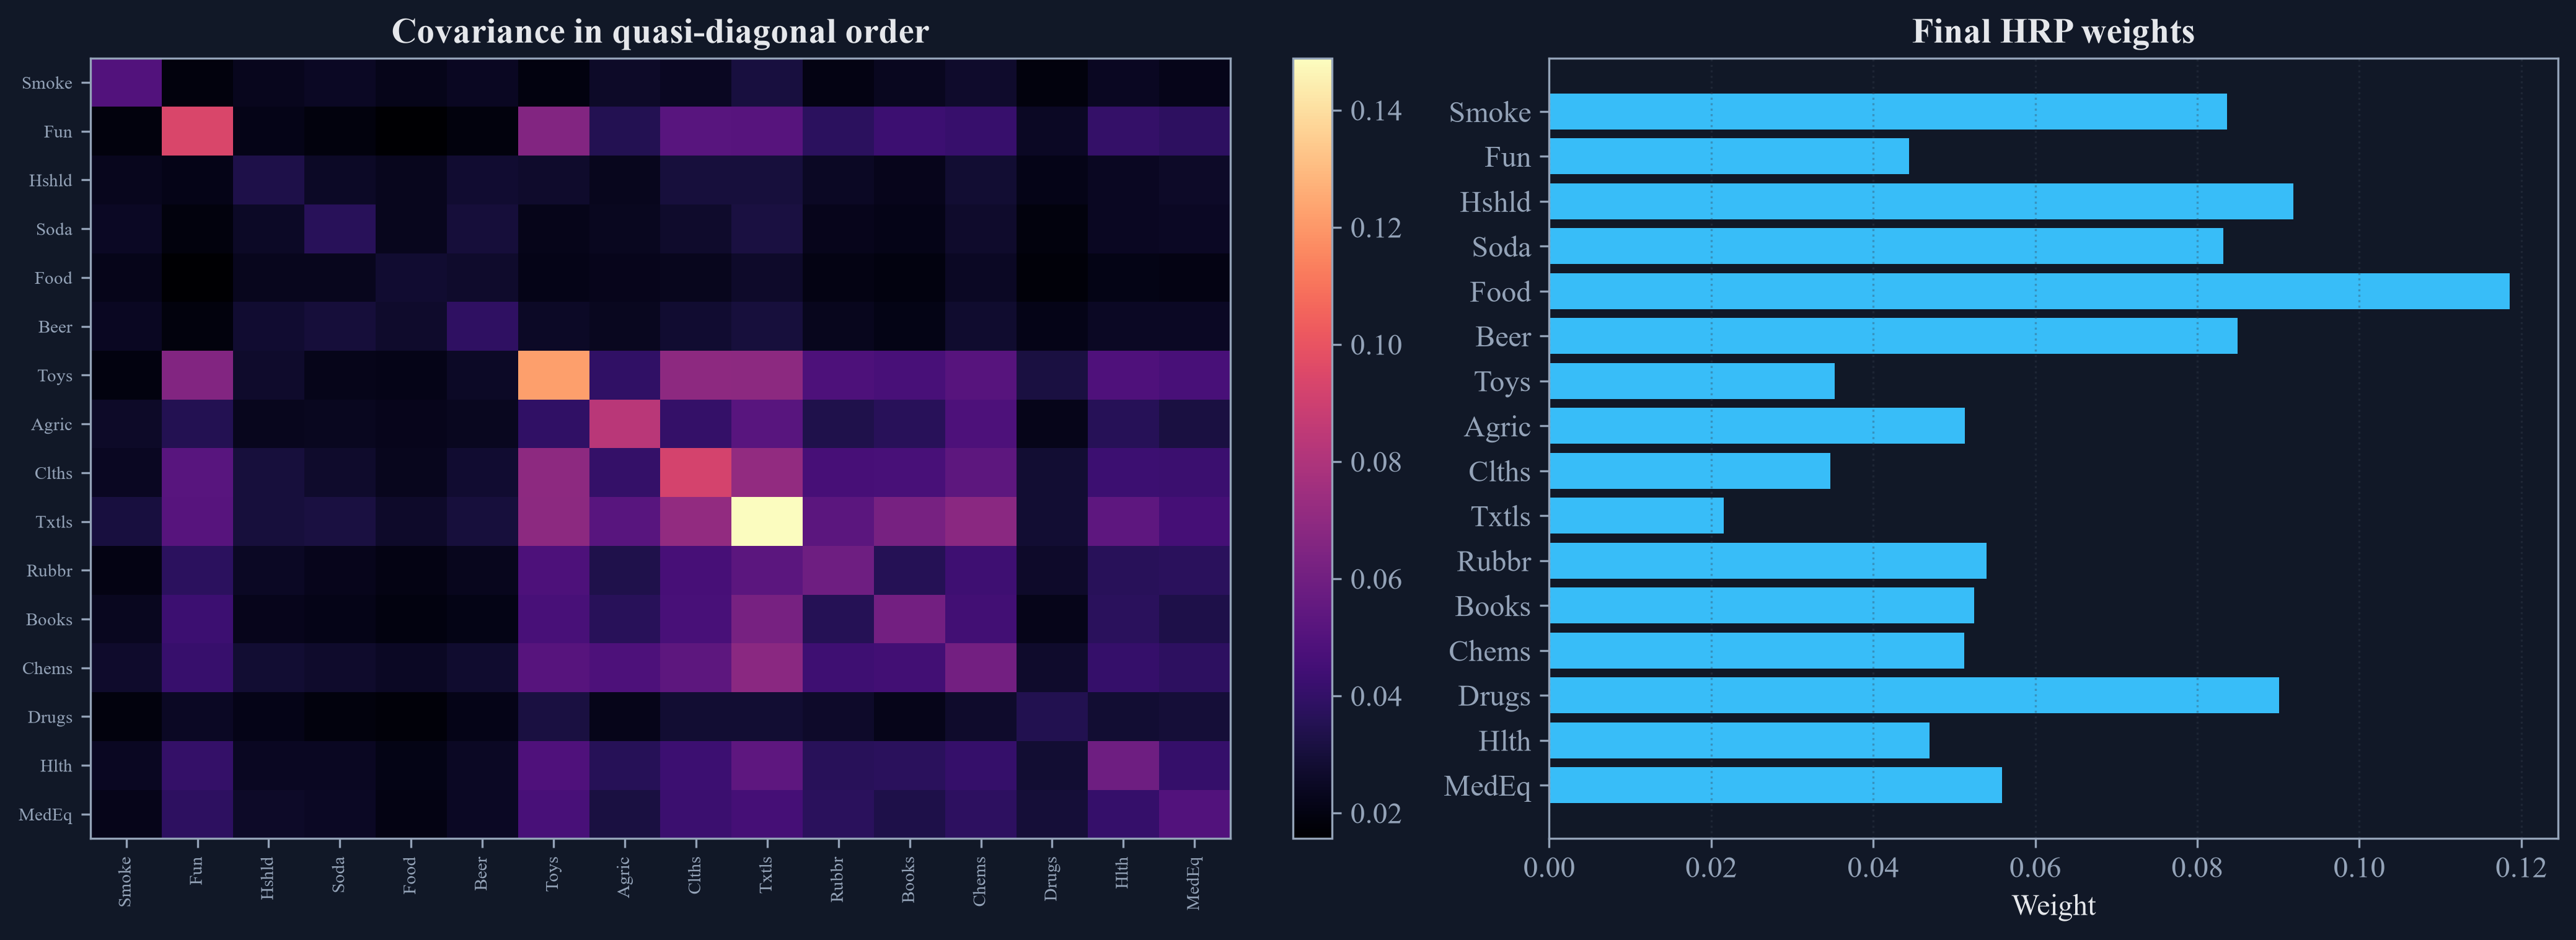

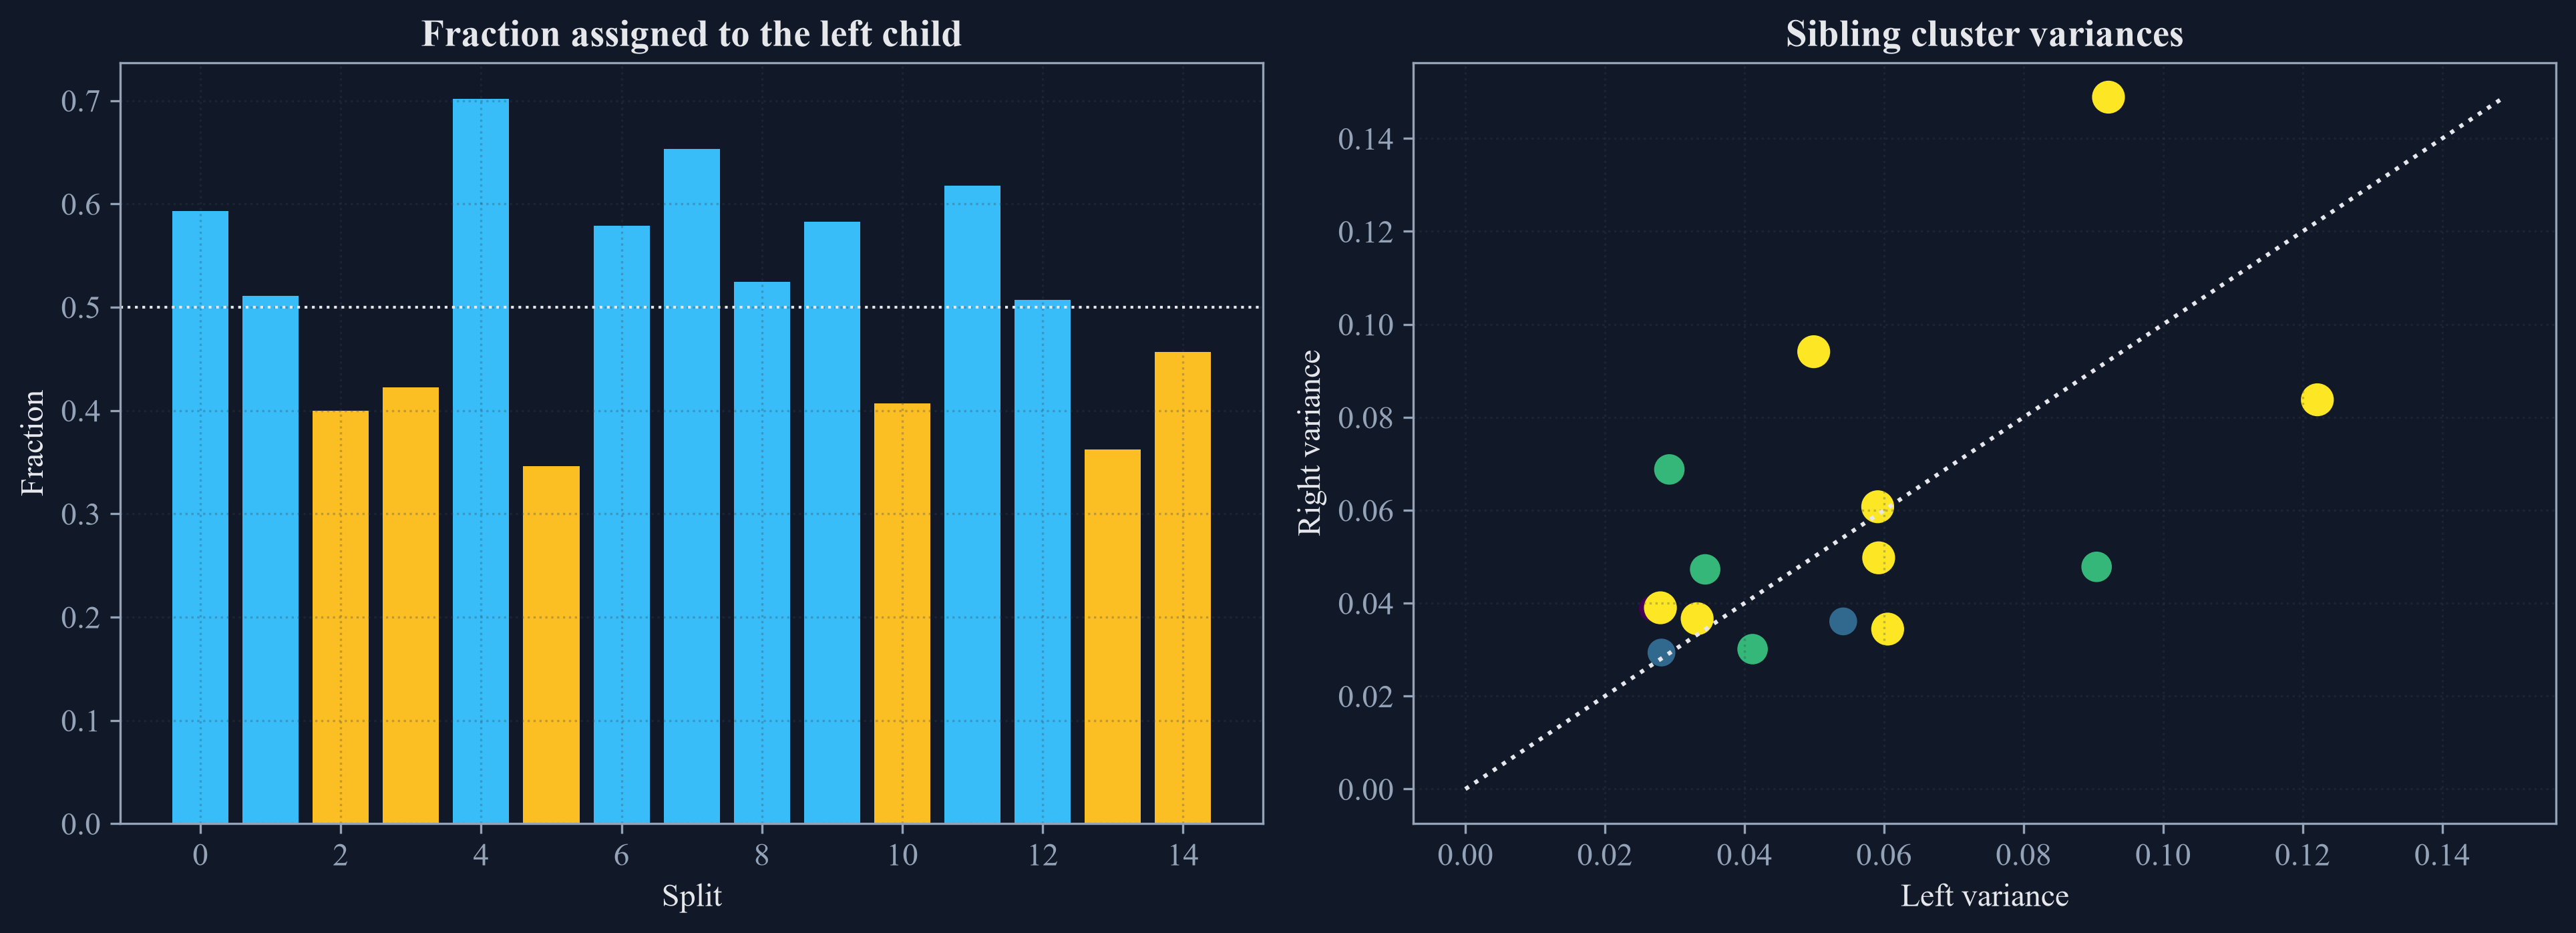

In [2]:
hrp_weights = released_weights.rename("HRP")
ivp_weights = inverse_variance_series(annual_covariance).rename("Inverse variance")
equal_weights = pd.Series(1.0 / len(selected_assets), index=selected_assets, name="Equal weight")
gmv_weights = global_minimum_variance(annual_covariance).rename("Minimum variance")
weight_table = pd.concat([hrp_weights, ivp_weights, equal_weights, gmv_weights], axis=1).reset_index(names="Industry")
portfolio_summary = pd.DataFrame([portfolio_metrics("HRP", hrp_weights, annual_covariance), portfolio_metrics("Inverse variance", ivp_weights, annual_covariance), portfolio_metrics("Equal weight", equal_weights, annual_covariance), portfolio_metrics("Minimum variance", gmv_weights, annual_covariance)])
save_table(weight_table, "public_portfolio_weights", "Public-sample weights for four portfolio rules.", "tab:chapter21-public-weights")
save_table(portfolio_summary, "public_portfolio_summary", "Public-sample portfolio summaries.", "tab:chapter21-public-portfolio-summary")
display(weight_table)
display(portfolio_summary)

ordered_covariance = annual_covariance.loc[single_order, single_order]
figure, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
image = axes[0].imshow(ordered_covariance.to_numpy(), cmap="magma", aspect="auto")
axes[0].set_title("Covariance in quasi-diagonal order")
axes[0].set_xticks(range(len(single_order)))
axes[0].set_yticks(range(len(single_order)))
axes[0].set_xticklabels(single_order, rotation=90, fontsize=7)
axes[0].set_yticklabels(single_order, fontsize=7)
figure.colorbar(image, ax=axes[0], fraction=0.046)
axes[1].barh(single_order, hrp_weights.reindex(single_order), color=palette["cyan"])
axes[1].invert_yaxis()
axes[1].set_title("Final HRP weights")
axes[1].set_xlabel("Weight")
axes[1].grid(axis="x", alpha=0.35)
figure.tight_layout()
save_figure(figure, "ordered_covariance_hrp_weights")

figure, axes = plt.subplots(1, 2, figsize=(13, 4.8))
split_positions = np.arange(len(branch_allocations))
colors = [palette["cyan"] if value >= 0.5 else palette["amber"] for value in branch_allocations["Left fraction"]]
axes[0].bar(split_positions, branch_allocations["Left fraction"], color=colors)
axes[0].axhline(0.5, color=palette["text"], linewidth=1, linestyle=":")
axes[0].set_title("Fraction assigned to the left child")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Fraction")
axes[1].scatter(branch_allocations["Left variance"], branch_allocations["Right variance"], s=45 + 18 * branch_allocations["Depth"], c=branch_allocations["Depth"], cmap="viridis")
maximum = float(branch_allocations[["Left variance", "Right variance"]].to_numpy().max())
axes[1].plot([0, maximum], [0, maximum], color=palette["text"], linestyle=":")
axes[1].set_title("Sibling cluster variances")
axes[1].set_xlabel("Left variance")
axes[1].set_ylabel("Right variance")
for axis in axes:
    axis.grid(alpha=0.3)
figure.tight_layout()
save_figure(figure, "recursive_split_diagnostics")

## Risk Contributions

The contribution of one asset to portfolio variance is its weight times its marginal variance:

$$
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad
\operatorname{RC}_i=w_i(\Sigma w)_i,
\qquad
\sum_{i=1}^{N}\operatorname{RC}_i=\sigma_p^2.
$$

Here, $w$ is the portfolio-weight vector, $\Sigma$ is the covariance matrix, $\sigma_p^2$ is portfolio variance, $(\Sigma w)_i$ is the marginal variance for asset $i$, $\operatorname{RC}_i$ is its variance contribution, and $N$ is the number of assets.

,Portfolio,Largest contribution share,Smallest contribution share,Contribution shares sum
0,Equal weight,0.096490,0.040451,1
1,HRP,0.093079,0.032792,1
2,Inverse variance,0.093078,0.033838,1
3,Minimum variance,0.489942,-0.167604,1


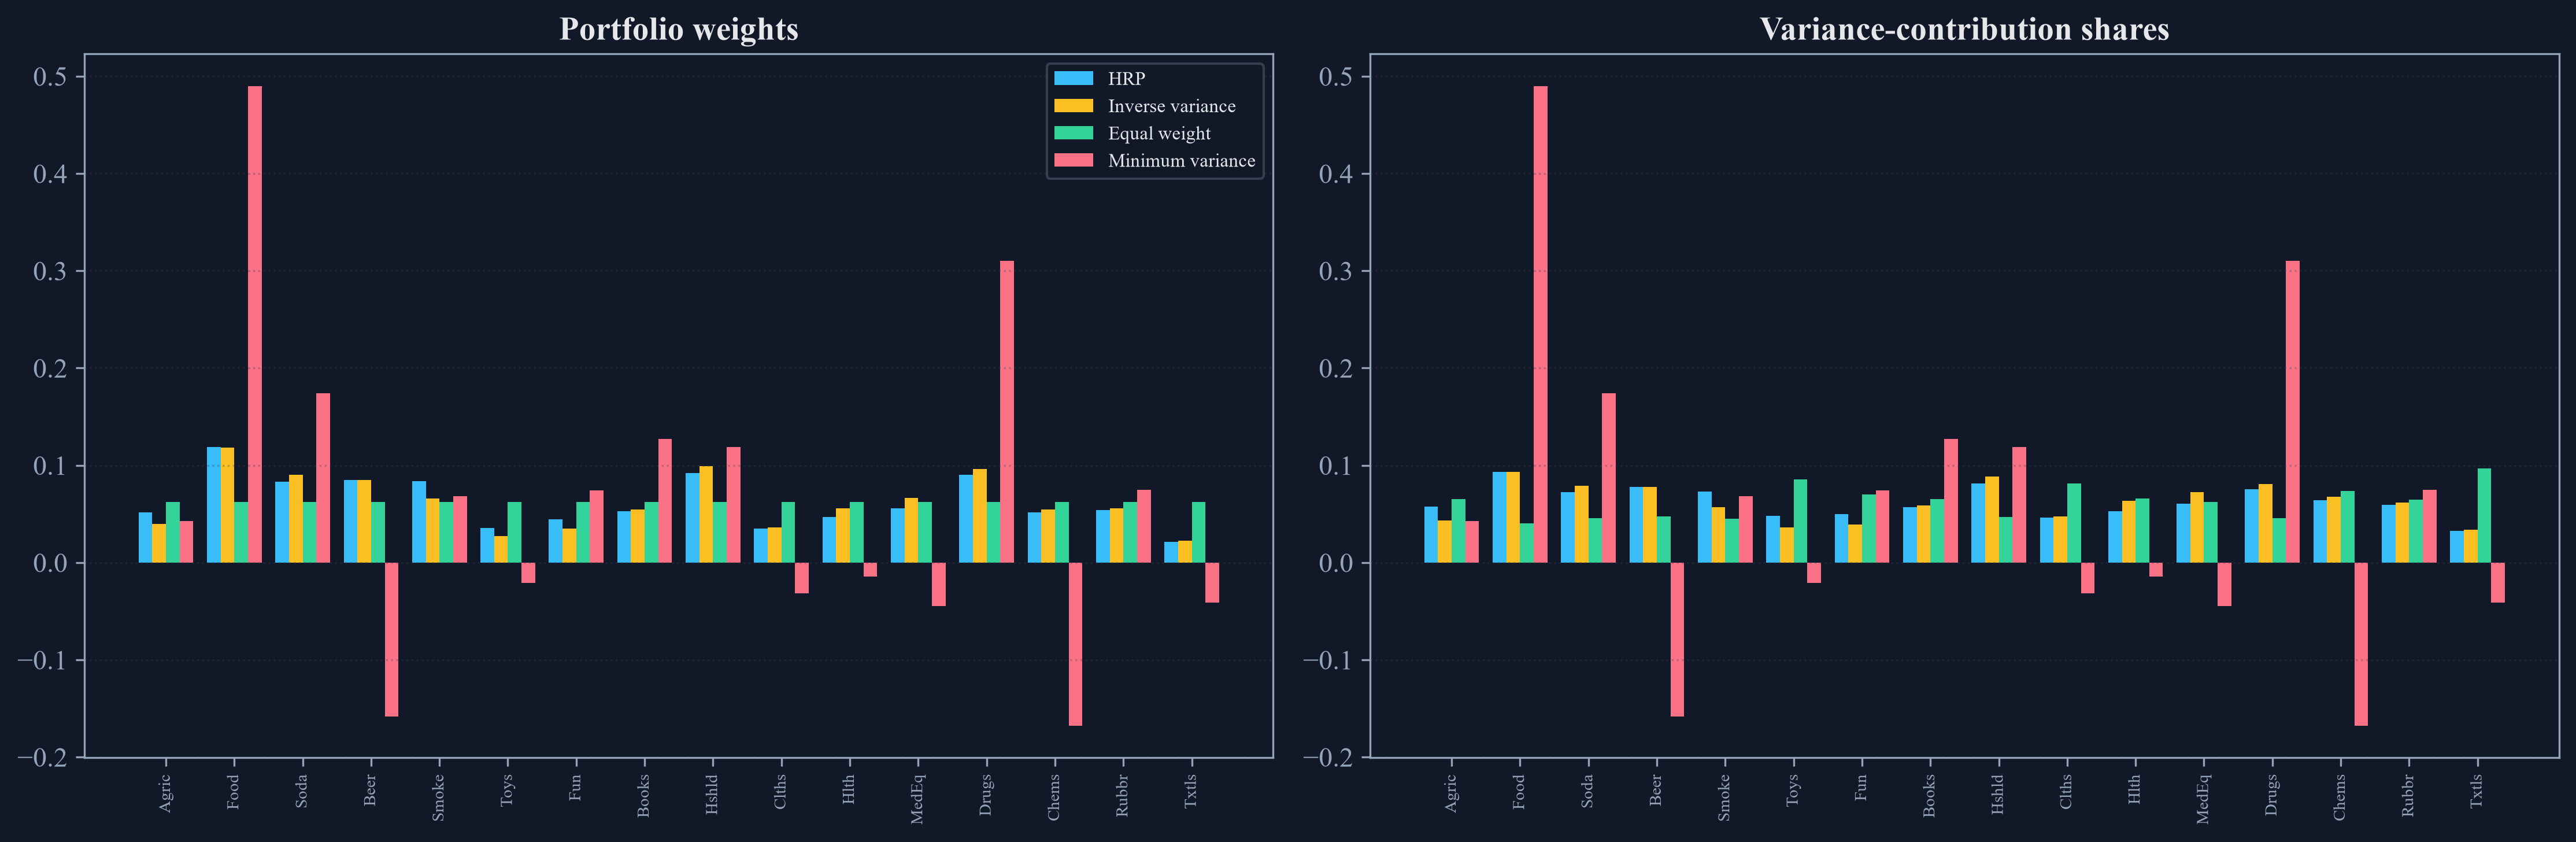

In [3]:
risk_rows = []
for portfolio_name, weights in {"HRP": hrp_weights, "Inverse variance": ivp_weights, "Equal weight": equal_weights, "Minimum variance": gmv_weights}.items():
    aligned = weights.reindex(selected_assets).to_numpy(dtype=float)
    marginal = annual_covariance.to_numpy() @ aligned
    contribution = aligned * marginal
    fraction = contribution / contribution.sum()
    for asset, weight, risk_fraction in zip(selected_assets, aligned, fraction):
        risk_rows.append({"Portfolio": portfolio_name, "Industry": asset, "Weight": weight, "Variance contribution share": risk_fraction})
risk_contributions = pd.DataFrame(risk_rows)
risk_summary = risk_contributions.groupby("Portfolio", as_index=False).agg(**{"Largest contribution share": ("Variance contribution share", "max"), "Smallest contribution share": ("Variance contribution share", "min"), "Contribution shares sum": ("Variance contribution share", "sum")})
save_table(risk_contributions, "risk_contributions", "Asset weights and variance-contribution shares.", "tab:chapter21-risk-contributions")
save_table(risk_summary, "risk_contribution_summary", "Portfolio variance-contribution summaries.", "tab:chapter21-risk-contribution-summary")
display(risk_summary)

figure, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(selected_assets))
width = 0.2
names = ["HRP", "Inverse variance", "Equal weight", "Minimum variance"]
colors = [palette["cyan"], palette["amber"], palette["green"], palette["rose"]]
for position, (name, color) in enumerate(zip(names, colors)):
    weights = weight_table.set_index("Industry")[name].reindex(selected_assets)
    shares = risk_contributions[risk_contributions["Portfolio"] == name].set_index("Industry")["Variance contribution share"].reindex(selected_assets)
    axes[0].bar(x + (position - 1.5) * width, weights, width=width, label=name, color=color)
    axes[1].bar(x + (position - 1.5) * width, shares, width=width, label=name, color=color)
axes[0].set_title("Portfolio weights")
axes[1].set_title("Variance-contribution shares")
for axis in axes:
    axis.set_xticks(x)
    axis.set_xticklabels(selected_assets, rotation=90, fontsize=7)
    axis.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)
figure.tight_layout()
save_figure(figure, "portfolio_weights_risk_contributions")

## Checking allocation under singular covariance

A covariance matrix is singular when at least one eigenvalue is zero:

$$
\det(\Sigma)=\prod_{k=1}^{N}\lambda_k=0.
$$

Here, $\Sigma$ is the covariance matrix, $\det(\Sigma)$ is its determinant, $\lambda_k$ is eigenvalue $k$, and $N$ is the number of assets; covariance inversion then fails, while recursive bisection can still use cluster variances.

,Check,Value
0,Released HRP equals traced bisection,0
1,Released HRP equals direct bisection,0
2,Cluster variance equals direct product,0
3,Singular covariance rank,7
4,Singular HRP budget,1
5,Slight asymmetry budget,1
6,One-asset bisection budget,1


,Quantity,Value
0,Singular assets,8
1,Singular rank,7
2,Smallest eigenvalue,0
3,Largest eigenvalue,2.905729e-01
4,Largest singular-case HRP weight,2.128899e-01
5,Smallest singular-case HRP weight,6.735337e-02


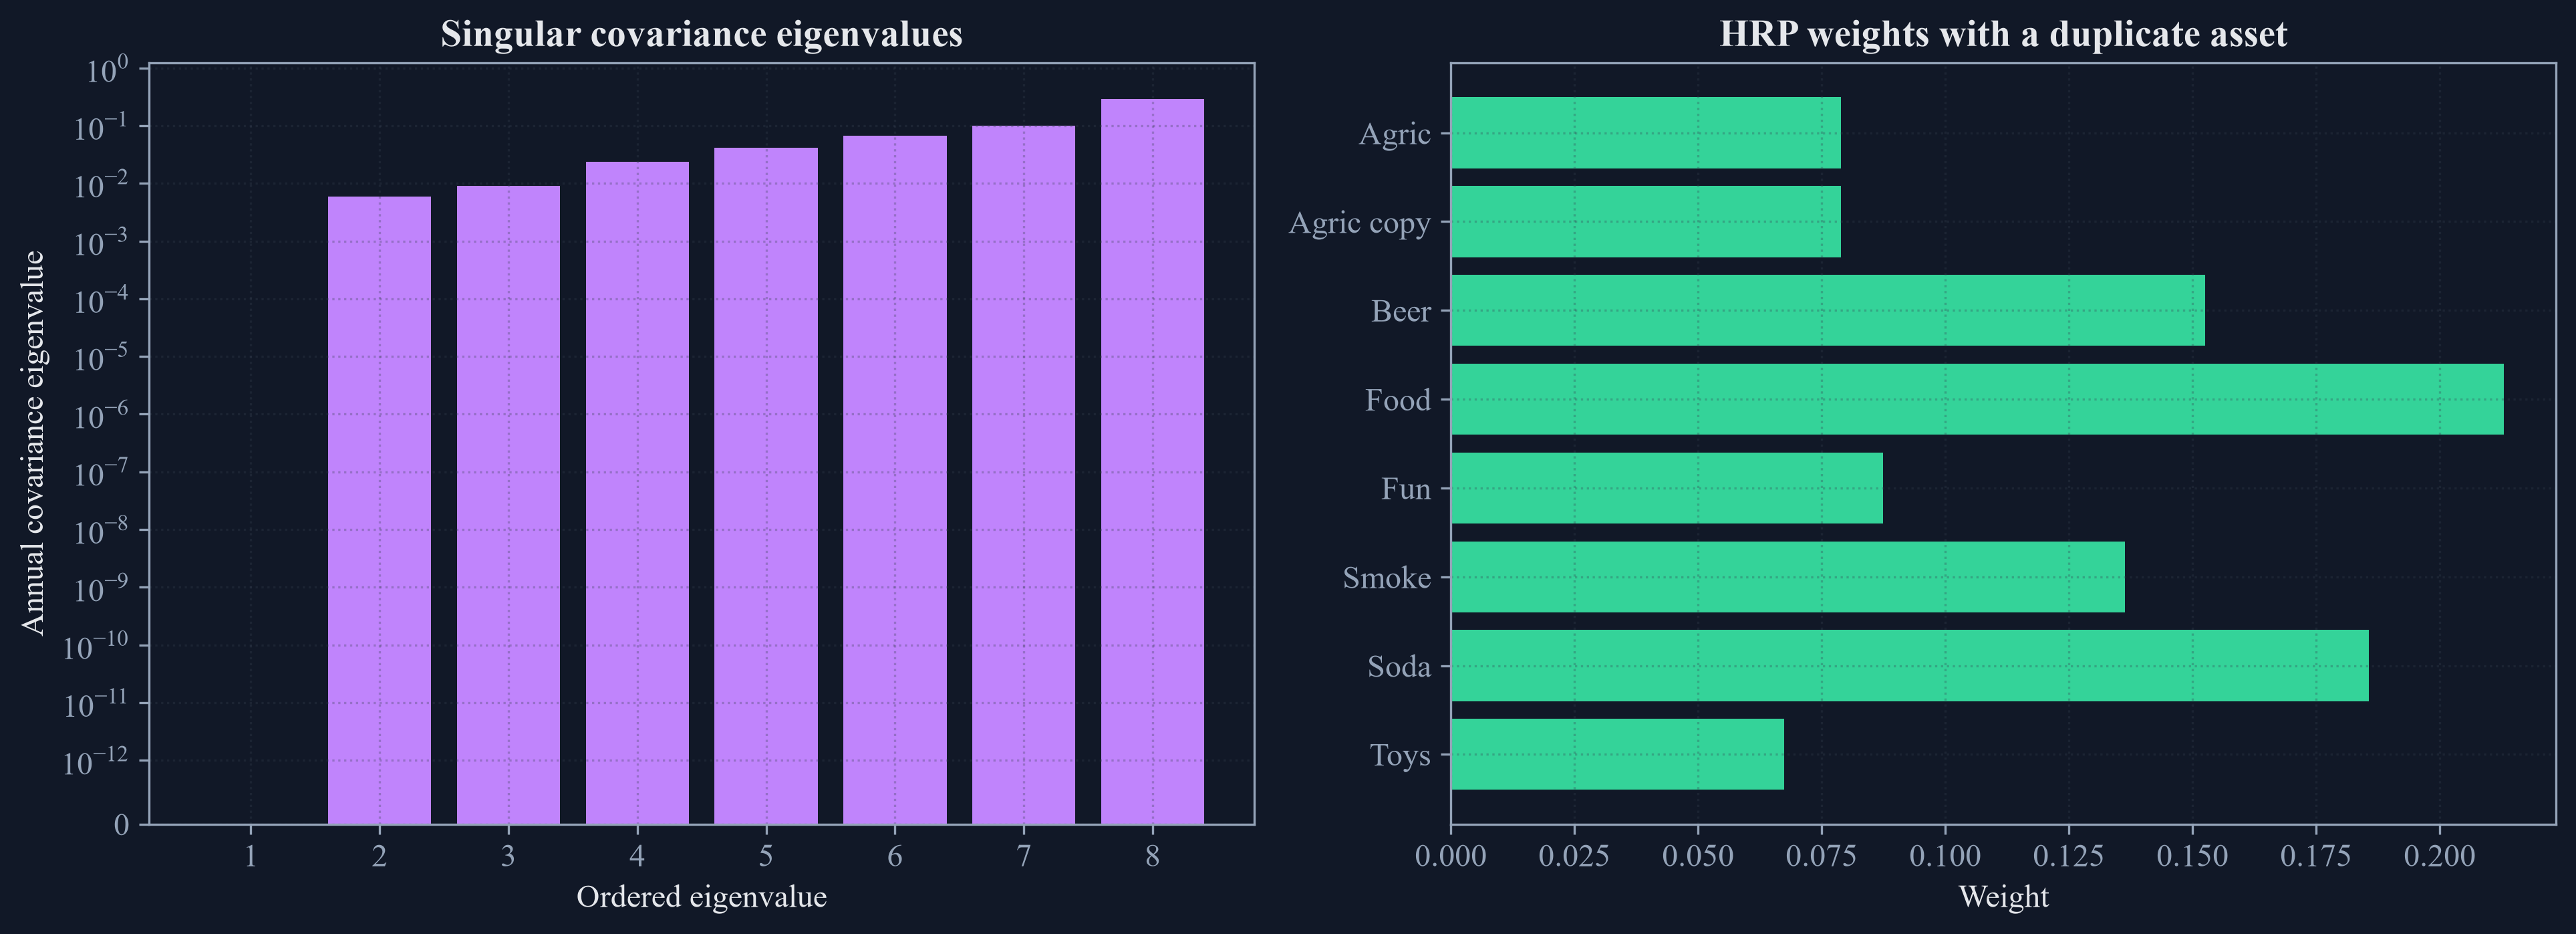

,Quantity,Value
0,Assets,16
1,Recursive splits,15
2,HRP budget,1
3,Minimum HRP weight,0.021505
4,Maximum HRP weight,0.118560
5,Public HRP annual volatility,0.169890
6,Singular example rank,7


In [4]:
duplicate_returns = public_sample.iloc[:, :7].copy()
duplicate_name = f"{duplicate_returns.columns[0]} copy"
duplicate_returns[duplicate_name] = duplicate_returns.iloc[:, 0]
singular_covariance = duplicate_returns.cov() * 252.0
singular_correlation = duplicate_returns.corr()
singular_weights = hrp(singular_covariance, singular_correlation)
singular_eigenvalues = np.linalg.eigvalsh(singular_covariance.to_numpy())
asymmetric_correlation = public_correlation.copy()
asymmetric_correlation.iloc[0, 1] += 1e-15
asymmetric_weights = hrp(annual_covariance, asymmetric_correlation)
one_asset_covariance = annual_covariance.iloc[:1, :1]
one_asset_weights = recursive_bisection(one_asset_covariance, [selected_assets[0]])
direct_cluster = annual_covariance.loc[single_order[:4], single_order[:4]]
direct_internal = inverse_variance_weights(direct_cluster)
direct_variance = float(direct_internal @ direct_cluster.to_numpy() @ direct_internal)
released_variance = cluster_variance(annual_covariance, single_order[:4])
calculation_checks = pd.DataFrame({"Check": ["Released HRP equals traced bisection", "Released HRP equals direct bisection", "Cluster variance equals direct product", "Singular covariance rank", "Singular HRP budget", "Slight asymmetry budget", "One-asset bisection budget"], "Value": [float(np.max(np.abs(released_weights.sort_index() - traced_weights.sort_index()))), float(np.max(np.abs(released_weights.sort_index() - direct_weights.sort_index()))), abs(released_variance - direct_variance), np.linalg.matrix_rank(singular_covariance.to_numpy()), singular_weights.sum(), asymmetric_weights.sum(), one_asset_weights.sum()]})
special_case_summary = pd.DataFrame({"Quantity": ["Singular assets", "Singular rank", "Smallest eigenvalue", "Largest eigenvalue", "Largest singular-case HRP weight", "Smallest singular-case HRP weight"], "Value": [len(singular_covariance), np.linalg.matrix_rank(singular_covariance.to_numpy()), singular_eigenvalues.min(), singular_eigenvalues.max(), singular_weights.max(), singular_weights.min()]})
save_table(calculation_checks, "released_calculation_checks", "Checks of the released HRP calculations.", "tab:chapter21-released-checks")
save_table(special_case_summary, "singular_case_summary", "Public duplicate-asset singular-covariance check.", "tab:chapter21-singular-summary")
display(calculation_checks)
display(special_case_summary)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(range(1, len(singular_eigenvalues) + 1), np.maximum(singular_eigenvalues, 0.0), color=palette["violet"])
axes[0].set_yscale("symlog", linthresh=1e-12)
axes[0].set_title("Singular covariance eigenvalues")
axes[0].set_xlabel("Ordered eigenvalue")
axes[0].set_ylabel("Annual covariance eigenvalue")
axes[1].barh(singular_weights.index, singular_weights.values, color=palette["green"])
axes[1].invert_yaxis()
axes[1].set_title("HRP weights with a duplicate asset")
axes[1].set_xlabel("Weight")
for axis in axes:
    axis.grid(alpha=0.3)
figure.tight_layout()
save_figure(figure, "singular_covariance_hrp")

allocation_section_summary = pd.DataFrame({"Quantity": ["Assets", "Recursive splits", "HRP budget", "Minimum HRP weight", "Maximum HRP weight", "Public HRP annual volatility", "Singular example rank"], "Value": [len(selected_assets), len(branch_allocations), hrp_weights.sum(), hrp_weights.min(), hrp_weights.max(), portfolio_summary.loc[portfolio_summary["Portfolio"] == "HRP", "Annual volatility"].iloc[0], np.linalg.matrix_rank(singular_covariance.to_numpy())]})
save_table(allocation_section_summary, "allocation_section_summary", "Section 21.2 numerical summary.", "tab:chapter21-allocation-summary")
display(allocation_section_summary)

## Tests

In [5]:
assert len(branch_allocations) == len(selected_assets) - 1
assert branch_allocations['Left fraction'].between(0.0, 1.0).all()
assert branch_allocations['Right fraction'].between(0.0, 1.0).all()
assert np.allclose(branch_allocations['Left fraction'] + branch_allocations['Right fraction'], 1.0)
assert np.allclose(released_weights.sort_index(), traced_weights.sort_index())
assert np.allclose(released_weights.sort_index(), direct_weights.sort_index())
assert np.isclose(released_weights.sum(), 1.0)
assert (released_weights >= 0.0).all()
assert np.isclose(ivp_weights.sum(), 1.0)
assert np.isclose(equal_weights.sum(), 1.0)
assert np.isclose(gmv_weights.sum(), 1.0)
assert np.isclose(released_variance, direct_variance)
assert risk_summary['Contribution shares sum'].sub(1.0).abs().max() < 1e-10
assert np.linalg.matrix_rank(singular_covariance.to_numpy()) < len(singular_covariance)
assert singular_eigenvalues.min() < 1e-12
assert np.isclose(singular_weights.sum(), 1.0)
assert (singular_weights >= 0.0).all()
assert (asymmetric_correlation.to_numpy() != asymmetric_correlation.to_numpy().T).any()
assert np.isclose(asymmetric_weights.sum(), 1.0)
assert np.isclose(one_asset_weights.iloc[0], 1.0)
assert (FIGURES / 'ordered_covariance_hrp_weights.pdf').is_file()
assert (FIGURES / 'recursive_split_diagnostics.pdf').is_file()
assert (FIGURES / 'portfolio_weights_risk_contributions.pdf').is_file()
assert (FIGURES / 'singular_covariance_hrp.pdf').is_file()
assert (TABLES / 'branch_allocations.tex').is_file()
assert (TABLES / 'released_calculation_checks.tex').is_file()
